# 6. Comparison with cogwheel

`cogwheel` marginalizes the extrinsic parameters of a template by quasi-Monte Carlo importance sampling. We compare it
with our likelihood ratio on the same segment and template, in the setting of a background search: no trigger (the
arrival time runs over the whole segment), no reference waveform search (the template is its own relative-binning
reference), and one construction plus one call per segment and template.

`../scripts/run_cogwheel.py` runs `cogwheel` at finer and finer settings on two segments of
`../data/segments/three_parameters.npz` (row 0, noise level, and row 4, a merger below threshold) and writes
`../data/results/cogwheel_row<row>.npz`; the settings are in its docstring. Here we compute our value for the same
templates and compare.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import numba
import matplotlib.pyplot as plt
import exmarg.search as search
from exmarg import figstyle

segments = '../data/segments/three_parameters.npz'
store = search.load_redshift_store('../tables/redshift', mmap=True)
cog = {row: np.load('../data/results/cogwheel_row%d.npz' % row) for row in (0, 4)}

## Our value, on one CPU core

The likelihood ratio of each template with the distance integrated over the prior uniform in volume, the prior of the
`cogwheel` runs. We time it on one core, as the `cogwheel` calls.

In [2]:
numba.set_num_threads(1)
ours, seconds = {}, {}
for row in (0, 4):
    bank = search.mass_bank(cog[row]['template'][None, :], segments, 'cpu')
    search.pe_intrinsic(segments, bank, store, rows=[row], prior='volume')          # compiles
    start = time.perf_counter()
    ours[row] = search.pe_intrinsic(segments, bank, store, rows=[row], prior='volume')['ln_lambda'][0, 0]
    seconds[row] = time.perf_counter() - start
    print('row %d: ln Lambda = %.4f in %.2f s on one core' % (row, ours[row], seconds[row]))

row 0: ln Lambda = -0.0124 in 2.62 s on one core


row 4: ln Lambda = 0.0641 in 2.62 s on one core


## The normalization of the arrival time

`cogwheel` integrates the arrival time over seconds, so its $\ln\Lambda$ exceeds ours by the logarithm of the width of
the window, $\ln 3.9$. Halving the window must lower it by $\ln 2$.

In [3]:
for row in (0, 4):
    lad, half = cog[row]['ladder'], cog[row]['half_window']
    print('row %d: halving the window moves ln Lambda by %.3f (ln 2 = %.3f)' % (row, half.mean() - lad[6, 2], np.log(2)))

row 0: halving the window moves ln Lambda by -0.693 (ln 2 = 0.693)
row 4: halving the window moves ln Lambda by -0.762 (ln 2 = 0.693)


## Accuracy against cost

The offset of `cogwheel` from our value, after removing $\ln 3.9$, at every setting, against the cost of one segment and
template: the construction plus one call. The error bars are the standard deviation of the repeated calls.

Noise Only: cogwheel offsets [-0.05  -0.061 -0.019 -0.017 -0.004 -0.011 -0.012 -0.013] at [15.8 15.8 16.  16.4 17.5 22.  22.6 49.7] s
Subthreshold Merger: cogwheel offsets [-0.107 -0.097 -0.044 -0.014 -0.008 -0.009 -0.012 -0.008] at [ 8.5  8.5  8.6  9.1 10.2 15.5 15.6 43.6] s


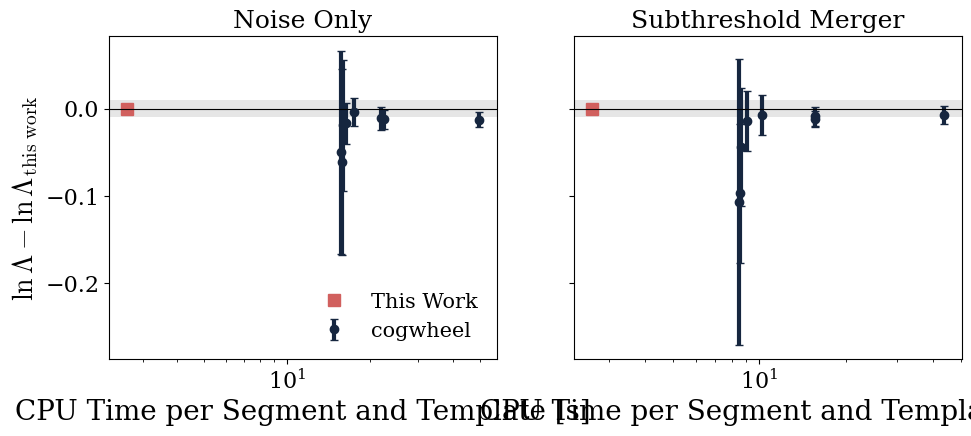

In [4]:
figstyle.apply()
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, row, title in zip(axs, (0, 4), ('Noise Only', 'Subthreshold Merger')):
    lad = cog[row]['ladder']
    offset = lad[:, 2] - np.log(float(cog[row]['t_range_width'])) - ours[row]
    cost = float(cog[row]['construction_s']) + lad[:, 4]
    ax.axhspan(-0.01, 0.01, color='0.9', lw=0)
    ax.errorbar(cost, offset, yerr=lad[:, 3], fmt='o', color=figstyle.NAVY, capsize=3, label='cogwheel')
    ax.plot(seconds[row], 0.0, 's', color=figstyle.RED, ms=9, label='This Work')
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xscale('log'); ax.set_title(title); ax.set_xlabel('CPU Time per Segment and Template [s]')
    print('%s: cogwheel offsets %s at %s s' % (title, np.round(offset, 3), np.round(cost, 1)))
axs[0].set_ylabel(r'$\ln\Lambda - \ln\Lambda_{\rm this\ work}$')
axs[0].legend(frameon=False, loc='lower right')
plt.show()

At its default setting `cogwheel` scatters by about 0.15 in $\ln\Lambda$ and lies below our value on average, and it
approaches our value as its number of samples grows, at a cost per segment and template that the figure compares with ours.